<a href="https://colab.research.google.com/github/angiemarian123456-art/METODOS-NUMERICOS-1/blob/main/Newton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iter (n)  p_0            p_n            Error (|p_n - p_0|)
-------------------------------------------------------
1         0.7853982    0.7395361    0.0458620
2         0.7395361    0.7390852    0.0004510
3         0.7390852    0.7390851    0.0000000

Raíz aproximada encontrada: p = 0.7390851
Total de iteraciones realizadas: 3



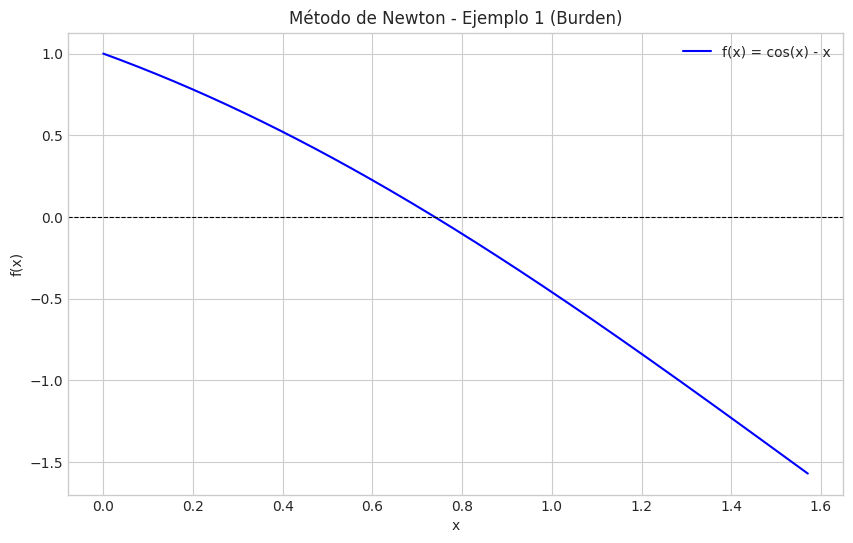

In [14]:
import numpy as np
import matplotlib.pyplot as plt

####IMPLEMENTACIÓN DEL ALGORITMO 2.3 MÉTODO DE NEWTON####
def metodo_newton(f, df, p0, tol, max_iter):
    i = 1
    historial = []

    # Ciclo
    while i <= max_iter:
        df_p0 = df(p0)
        if df_p0 == 0:
            print("La derivada es cero. El método no puede continuar.")
            return None, historial

        p = p0 - f(p0) / df_p0
        error = abs(p - p0)

        # Guardamos los datos para la tabla
        historial.append([i, p0, p, error])

        # Criterio (si el error es menor a la tolerancia)
        if error < tol:
            return p, historial

        i += 1
        p0 = p

    print("El método falló después de alcanzar el máximo de iteraciones.")
    return p, historial

####DEFINICIÓN DE LA FUNCIÓN/EJEMPLO DEL LIBRO####
# Usamos el ejemplo 1 del libro: f(x) = cos(x) - x y su derivada f'(x) = -sin(x) - 1
def f(x):
    return np.cos(x) - x

def df(x):
    return -np.sin(x) - 1

# Parámetros
p0_inicial = np.pi / 4
tolerancia = 1e-7
max_iteraciones = 20

# Ejecutamos
raiz, tabla = metodo_newton(f, df, p0_inicial, tolerancia, max_iteraciones)

# Imprimimos
print(f"{'Iter (n)':<10}{'p_0':<15}{'p_n':<15}{'Error (|p_n - p_0|)':<15}")
print("-" * 55)
for fila in tabla:
    print(f"{fila[0]:<10}{fila[1]:.7f}    {fila[2]:.7f}    {fila[3]:.7f}")

print("\n" + "="*45)
print(f"Raíz aproximada encontrada: p = {raiz:.7f}")
print(f"Total de iteraciones realizadas: {len(tabla)}")
print("="*45 + "\n")

####GRAFICA####
# Generamos puntos para graficar f(x)
x_vals = np.linspace(0, np.pi/2, 200)
y_vals = f(x_vals)

plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_vals, label='f(x) = cos(x) - x', color='blue', linewidth=1.5)
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Método de Newton - Ejemplo 1 (Burden)')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()